# Modul 10 — Analisis Shift dan Regu
**Pertanyaan operasional:** apakah ada shift (Pagi, Siang, Malam) atau regu (A–D) yang secara sistematis lebih produktif, lebih hemat energi, atau lebih sering mengalami downtime?

Perangkap yang akan kita hindari: (1) membandingkan total output padahal jam operasi berbeda (pakai **ton per jam operasi**), (2) mengabaikan bahwa tiga shift dalam satu hari saling terkait (hari yang bagus menaikkan ketiganya), (3) menarik kesimpulan "tidak ada beda" tanpa tahu **seberapa kecil beda yang sanggup kita deteksi** (daya uji).

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
sh = pd.read_excel(XLSX, sheet_name="Produksi_Shift"); sh["Tanggal"] = pd.to_datetime(sh["Tanggal"])
rng = np.random.default_rng(10)
sh["ton_per_jam"] = np.where(sh.Jam_Operasi > 0, sh.Katoda_Cu_t / sh.Jam_Operasi.replace(0, np.nan), np.nan)
sh["energi_per_t"] = sh.Energi_MWh / sh.Katoda_Cu_t.replace(0, np.nan)
print(sh.head(6).round(2).to_string(index=False))
print("\nBaris:", len(sh), "| shift beroperasi penuh (8 jam):", (sh.Jam_Operasi == 8).sum(), "| shift dengan downtime:", (sh.Jam_Downtime > 0).sum())

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx
ID_Shift    Tanggal Shift Regu  Jam_Operasi  Jam_Downtime  Katoda_Cu_t  Energi_MWh  ton_per_jam  energi_per_t
 SH-0001 2026-01-01  Pagi    A          8.0           0.0        219.1         314        27.39          1.43
 SH-0002 2026-01-01 Siang    B          8.0           0.0        208.2         311        26.02          1.49
 SH-0003 2026-01-01 Malam    C          8.0           0.0        202.5         339        25.31          1.67
 SH-0004 2026-01-02  Pagi    B          8.0           0.0        208.5         314        26.06          1.51
 SH-0005 2026-01-02 Siang    C          8.0           0.0        212.4         327        26.55          1.54
 SH-0006 2026-01-02 Malam    D          8.0           0.0        215.6         294        26.95          1.36

Baris: 819 | shift beroperasi penuh (8 jam): 737 | shift dengan downtime: 82


## 1. Gambaran awal
Untuk produktivitas dan energi/t, bandingkan hanya **shift beroperasi penuh (8 jam)**. Shift yang sebagian berhenti mempunyai pola energi berbeda (pemanasan ulang) dan akan mengaburkan perbandingan.

In [ ]:
penuh = sh[sh.Jam_Operasi == 8].copy()
for faktor in ["Shift", "Regu"]:
    t = penuh.groupby(faktor).agg(n=("ton_per_jam", "size"), ton_per_jam=("ton_per_jam", "mean"), sd=("ton_per_jam", "std"), energi_per_t=("energi_per_t", "mean"))
    print(f"\nPer {faktor} (shift penuh):"); print(t.round(3))
dt = sh.groupby("Shift").agg(jam_downtime=("Jam_Downtime", "sum"), shift_terganggu=("Jam_Downtime", lambda s: (s > 0).sum()))
print("\nDowntime per shift:"); print(dt)


Per Shift (shift penuh):
         n  ton_per_jam     sd  energi_per_t
Shift                                       
Malam  250       25.130  1.407         1.463
Pagi   250       25.143  1.383         1.459
Siang  237       25.096  1.319         1.464

Per Regu (shift penuh):
        n  ton_per_jam     sd  energi_per_t
Regu                                       
A     180       25.142  1.469         1.452
B     188       25.229  1.436         1.453
C     186       25.001  1.246         1.473
D     183       25.121  1.317         1.470

Downtime per shift:
       jam_downtime  shift_terganggu
Shift                               
Malam          68.0               23
Pagi          114.0               23
Siang         147.5               36


## 2. Uji beda antar kelompok
- **ANOVA satu arah** (membandingkan rata-rata; asumsi normal dan varians sama).
- **Kruskal–Wallis** (berbasis peringkat; tanpa asumsi normal).
- **Ukuran efek:** η² (porsi variasi yang dijelaskan faktor) untuk ANOVA dan ε² untuk Kruskal–Wallis.

η² ≈ 0,01 kecil, 0,06 sedang, 0,14 besar.

In [ ]:
def uji_kelompok(df, faktor, y):
    grup = [g[y].dropna().values for _, g in df.groupby(faktor)]
    F, pF = stats.f_oneway(*grup); H, pH = stats.kruskal(*grup)
    n = sum(len(g) for g in grup); k = len(grup)
    eta2 = (F * (k - 1)) / (F * (k - 1) + (n - k)); eps2 = H * (n + 1) / (n**2 - 1)
    return dict(faktor=faktor, metrik=y, F=F, p_ANOVA=pF, eta2=eta2, H=H, p_KW=pH, eps2=eps2)
hasil = pd.DataFrame([uji_kelompok(penuh, f, m) for f in ["Shift", "Regu"] for m in ["ton_per_jam", "energi_per_t"]])
print(hasil.round(4).to_string(index=False))

faktor       metrik      F  p_ANOVA   eta2      H   p_KW   eps2
 Shift  ton_per_jam 0.0757   0.9271 0.0002 0.1388 0.9330 0.0002
 Shift energi_per_t 0.2620   0.7696 0.0007 0.5780 0.7490 0.0008
  Regu  ton_per_jam 0.8816   0.4502 0.0036 2.6270 0.4528 0.0036
  Regu energi_per_t 2.6447   0.0482 0.0107 7.7464 0.0516 0.0105


## 3. Mengontrol efek hari (shift dalam hari yang sama)
Tiga shift di hari yang sama berbagi bahan baku, cuaca, dan kondisi tungku. Cara sederhana mengontrolnya: kurangi tiap nilai dengan **rata-rata harian**-nya (setara efek tetap per hari). Lalu uji faktor pada sisa variasi tersebut. Kita pakai hari yang semua shift-nya beroperasi penuh.

In [ ]:
hari_penuh = sh.groupby("Tanggal").Jam_Operasi.transform("min") == 8
d = sh[hari_penuh].copy()
for m in ["ton_per_jam", "energi_per_t"]:
    d[m + "_adj"] = d[m] - d.groupby("Tanggal")[m].transform("mean")
print(f"Hari dengan ketiga shift penuh: {d.Tanggal.nunique()} hari ({len(d)} shift)")
adj = pd.DataFrame([uji_kelompok(d, f, m + "_adj") for f in ["Shift", "Regu"] for m in ["ton_per_jam", "energi_per_t"]])
print(adj.round(4).to_string(index=False))

# Friedman: uji berpasangan antar 3 shift pada hari yang sama (tanpa asumsi normal)
w = d.pivot(index="Tanggal", columns="Shift", values="ton_per_jam").dropna()
fr = stats.friedmanchisquare(*[w[c] for c in w.columns]); print(f"\nFriedman (ton/jam antar shift, hari sama; n hari={len(w)}): chi²={fr.statistic:.2f}, p={fr.pvalue:.3f}")

Hari dengan ketiga shift penuh: 206 hari (618 shift)
faktor           metrik      F  p_ANOVA   eta2      H   p_KW   eps2
 Shift  ton_per_jam_adj 0.7064   0.4938 0.0023 1.3758 0.5026 0.0022
 Shift energi_per_t_adj 1.4811   0.2282 0.0048 2.5692 0.2768 0.0042
  Regu  ton_per_jam_adj 2.8330   0.0376 0.0137 5.9220 0.1155 0.0096
  Regu energi_per_t_adj 3.3246   0.0194 0.0160 8.6676 0.0341 0.0140

Friedman (ton/jam antar shift, hari sama; n hari=206): chi²=1.14, p=0.567


## 4. Dua faktor sekaligus: Shift dan Regu
Regu bergilir antar shift, jadi dua faktor saling silang. Uji F bertingkat (model dengan vs tanpa faktor) pada nilai yang sudah dikoreksi harian:

In [ ]:
def dummies(s): return pd.get_dummies(s, drop_first=True).astype(float).values
def sse(y, X):
    X = np.column_stack([np.ones(len(y)), X]) if X is not None else np.ones((len(y), 1))
    b = np.linalg.lstsq(X, y, rcond=None)[0]; r = y - X @ b; return r @ r, X.shape[1]
def f_tambahan(y, X_penuh, X_kecil):
    s1, p1 = sse(y, X_penuh); s0, p0 = sse(y, X_kecil); n = len(y)
    F = ((s0 - s1) / (p1 - p0)) / (s1 / (n - p1)); return F, stats.f.sf(F, p1 - p0, n - p1)
y = d.ton_per_jam_adj.values; S_, R_ = dummies(d.Shift), dummies(d.Regu)
both = np.column_stack([S_, R_])
print("Faktor Shift (dengan Regu dikendalikan): F=%.2f, p=%.3f" % f_tambahan(y, both, R_))
print("Faktor Regu (dengan Shift dikendalikan): F=%.2f, p=%.3f" % f_tambahan(y, both, S_))
inter = np.column_stack([both] + [S_[:, [i]] * R_[:, [j]] for i in range(S_.shape[1]) for j in range(R_.shape[1])])
print("Interaksi Shift x Regu             : F=%.2f, p=%.3f" % f_tambahan(y, inter, both))

Faktor Shift (dengan Regu dikendalikan): F=0.66, p=0.516
Faktor Regu (dengan Shift dikendalikan): F=2.80, p=0.039
Interaksi Shift x Regu             : F=0.55, p=0.771


## 5. Downtime: apakah terkonsentrasi pada shift tertentu?
Jam downtime per shift dibandingkan dengan harapan jika tersebar merata. Uji permutasi: acak label shift dalam tiap hari, hitung selisih terbesar antar shift.

In [ ]:
obs = sh.groupby("Shift").Jam_Downtime.sum().values; stat_obs = obs.max() - obs.min()
H = sh.pivot(index="Tanggal", columns="Shift", values="Jam_Downtime").values
def acak():
    M = np.apply_along_axis(rng.permutation, 1, H); t = M.sum(axis=0); return t.max() - t.min()
null = np.array([acak() for _ in range(3000)])
print("Total jam per shift:", dict(zip(sorted(sh.Shift.unique()), obs)), f"| selisih maks={stat_obs:.1f} jam")
print(f"p permutasi = {(null >= stat_obs).mean():.3f}   (selisih maks yang wajar secara acak: median {np.median(null):.1f}, P95 {np.percentile(null, 95):.1f})")

Total jam per shift: {'Malam': np.float64(68.0), 'Pagi': np.float64(114.0), 'Siang': np.float64(147.5)} | selisih maks=79.5 jam
p permutasi = 0.027   (selisih maks yang wajar secara acak: median 34.5, P95 72.0)


## 6. Daya uji: seberapa kecil perbedaan yang sanggup kita deteksi?
"Tidak signifikan" hanya berarti sesuatu bila ujinya cukup kuat. Hitung **selisih terkecil yang terdeteksi dengan daya 80%** untuk dua kelompok (α = 5%): `MDE = (z_{α/2} + z_β) · σ · √(2/n)`.

In [ ]:
sd_ = penuh.ton_per_jam.std(); mu_ = penuh.ton_per_jam.mean()
for nama, n_ in [("per shift (≈ tiga kelompok)", penuh.groupby("Shift").size().min()), ("per regu", penuh.groupby("Regu").size().min())]:
    mde = (stats.norm.ppf(.975) + stats.norm.ppf(.80)) * sd_ * np.sqrt(2 / n_)
    print(f"{nama:30s}: n per kelompok={n_:3d} -> MDE = {mde:.3f} ton/jam = {mde/mu_*100:.1f}% dari rata-rata")
sd_adj = d.ton_per_jam_adj.std(); n_h = d.groupby("Shift").size().min()
mde_adj = (stats.norm.ppf(.975) + stats.norm.ppf(.80)) * sd_adj * np.sqrt(2 / n_h)
print(f"Setelah koreksi harian: MDE = {mde_adj:.3f} ton/jam = {mde_adj/mu_*100:.1f}% dari rata-rata (lebih kecil karena variasi antar-hari dibuang)")

per shift (≈ tiga kelompok)   : n per kelompok=237 -> MDE = 0.352 ton/jam = 1.4% dari rata-rata
per regu                      : n per kelompok=180 -> MDE = 0.404 ton/jam = 1.6% dari rata-rata
Setelah koreksi harian: MDE = 0.221 ton/jam = 0.9% dari rata-rata (lebih kecil karena variasi antar-hari dibuang)


## 7. Pelajaran penting: banyak uji, satu temuan "hampir signifikan"
Kita sudah menjalankan belasan uji. Beberapa menghasilkan p ≈ 0,02–0,05 (misalnya faktor regu pada energi/t, dan downtime per shift). Jika menguji 13 hipotesis yang semuanya benar-benar nol, peluang **minimal satu** p < 0,05 adalah 1 − 0,95¹³ ≈ 49%. Maka seluruh keluarga uji harus dikoreksi bersama (**Holm**), dan ukuran efek harus dibaca (η² ≈ 0,01 itu *kecil*).

In [ ]:
keluarga = {}
for _, r in hasil.iterrows(): keluarga[f"ANOVA {r.faktor} - {r.metrik}"] = r.p_ANOVA
for _, r in adj.iterrows(): keluarga[f"ANOVA harian-adj {r.faktor} - {r.metrik}"] = r.p_ANOVA
keluarga["Friedman shift (ton/jam)"] = fr.pvalue
keluarga["Dua faktor: Shift"] = f_tambahan(y, both, R_)[1]; keluarga["Dua faktor: Regu"] = f_tambahan(y, both, S_)[1]; keluarga["Dua faktor: Interaksi"] = f_tambahan(y, inter, both)[1]
keluarga["Downtime per shift (permutasi)"] = (null >= stat_obs).mean()
fam = pd.Series(keluarga).sort_values(); m = len(fam); holm = np.minimum(1, np.maximum.accumulate(fam.values * (m - np.arange(m))))
tab = pd.DataFrame({"p_mentah": fam.values, "p_Holm": holm}, index=fam.index)
print(f"{m} uji dalam keluarga; p<0,05 sebelum koreksi: {(tab.p_mentah<.05).sum()} | setelah Holm: {(tab.p_Holm<.05).sum()}")
print(tab.round(3).head(6))

13 uji dalam keluarga; p<0,05 sebelum koreksi: 5 | setelah Holm: 0
                                           p_mentah  p_Holm
ANOVA harian-adj Regu - energi_per_t_adj      0.019   0.252
Downtime per shift (permutasi)                0.027   0.324
ANOVA harian-adj Regu - ton_per_jam_adj       0.038   0.414
Dua faktor: Regu                              0.039   0.414
ANOVA Regu - energi_per_t                     0.048   0.434
ANOVA harian-adj Shift - energi_per_t_adj     0.228   1.000


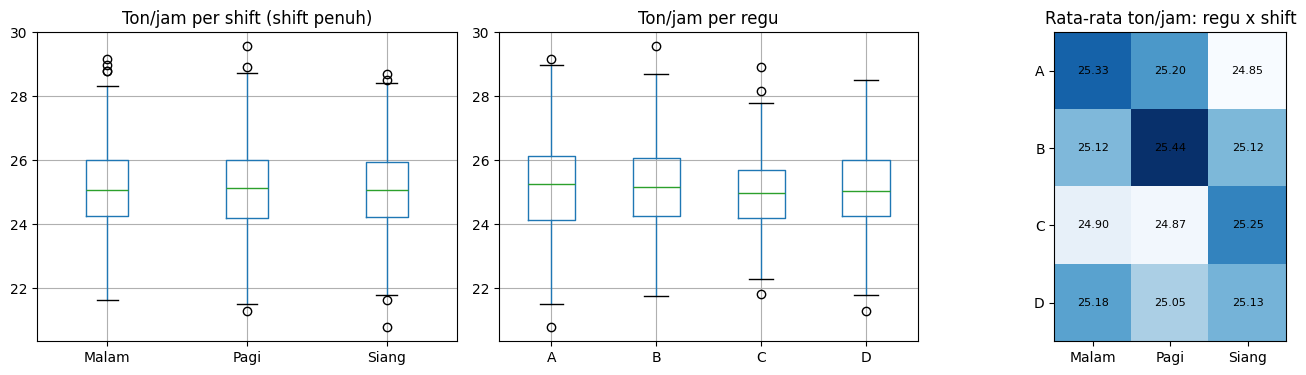

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
penuh.boxplot(column="ton_per_jam", by="Shift", ax=ax[0]); ax[0].set_title("Ton/jam per shift (shift penuh)"); ax[0].set_xlabel("")
penuh.boxplot(column="ton_per_jam", by="Regu", ax=ax[1]); ax[1].set_title("Ton/jam per regu"); ax[1].set_xlabel("")
pv = penuh.pivot_table(index="Regu", columns="Shift", values="ton_per_jam", aggfunc="mean"); im = ax[2].imshow(pv.values, cmap="Blues"); ax[2].set_xticks(range(3)); ax[2].set_xticklabels(pv.columns); ax[2].set_yticks(range(4)); ax[2].set_yticklabels(pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]): ax[2].text(j, i, f"{pv.values[i,j]:.2f}", ha="center", va="center", fontsize=8)
ax[2].set_title("Rata-rata ton/jam: regu x shift"); plt.suptitle(""); plt.tight_layout(); plt.show()

**Kesimpulan modul 10.**
*   Tidak ada perbedaan shift (Friedman p = 0,567). Regu terlihat berbeda sebelum koreksi (p 0,019–0,048), tetapi setelah koreksi Holm p-nya 0,25–0,43.
*   Data hanya dapat mendeteksi selisih sekitar 0,9–1,6% sehingga disimpulkan tidak ada perbedaan operasional yang berarti antar shift/regu maka jangan menindak regu atau shift.

